# Compression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.fftpack as fft
import skimage.io as io

import matplotlib as mpl
plt.style.use('../../src/bip.mplstyle')
mpl.rcParams['xtick.bottom'] = False
mpl.rcParams['ytick.left'] = False
plt.rcParams['image.cmap'] = 'gray'

## RLE

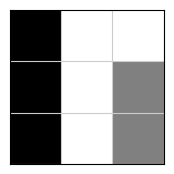

In [2]:
fig = plt.figure(figsize=(2,2))
img = np.array([[0, 255, 255], [0, 255, 128], [0, 255, 128]])
plt.imshow(img)
ax = plt.gca()
plt.xticks(np.arange(.495,3), labels=[])
plt.yticks(np.arange(.5,3), labels=[])
ax.grid(color='#cccccc')
plt.savefig("rle.svg")

## DCT

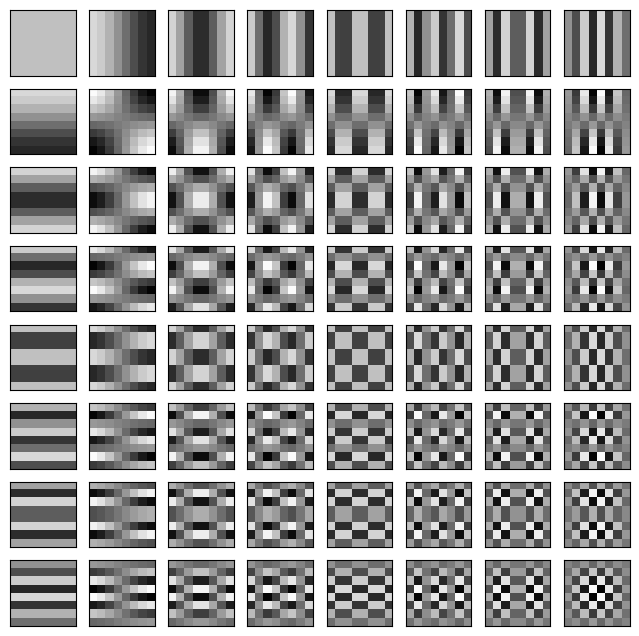

In [3]:
fig = plt.figure(figsize=(8,8))
for x in range(8):
    for y in range(8):
    
        # DCT (nulle partout sauf au pixel p)
        F = np.zeros((8,8))
        F[y,x] = 1

        # DCT inverse (ne pas oublier l'option norm='ortho' !)
        f = fft.idctn(F, norm='ortho')
        
        # Affichage de l'image de la base
        plt.subplot(8, 8, 8*y+x+1)
        plt.imshow(f, "gray", vmin=-.25, vmax=.25)
        plt.xticks([])
        plt.yticks([])
        
plt.savefig("dct-coefficients.svg")

## JPEG

### Load and crop

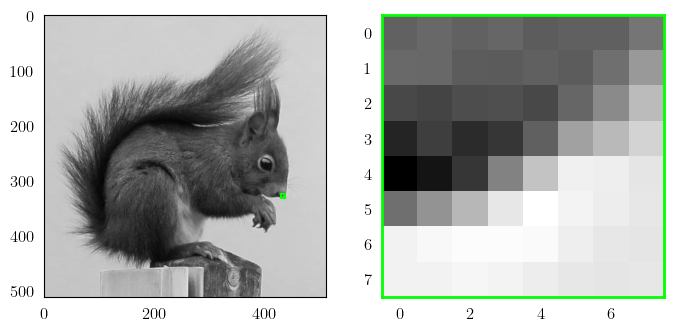

In [4]:
img = io.imread("../../src/figs/squirrel.png")

# Crop coordinates
x1, y1 = 430, 325
x2, y2 = x1+8, y1+8
crop = img[y1:y2, x1:x2]

# Entire image & crop
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(img, "gray")
axs[0].plot([x1, x1, x2, x2, x1], [y1, y2, y2, y1, y1], color="#00ff00")
axs[1].imshow(crop, "gray")
for pos in ['bottom', 'top', 'left', 'right']:
    axs[1].spines[pos].set_color('#00ff00')
    axs[1].spines[pos].set_linewidth(2)

# Save image
plt.savefig("squirrel-crop.svg")

### Compression of the crop

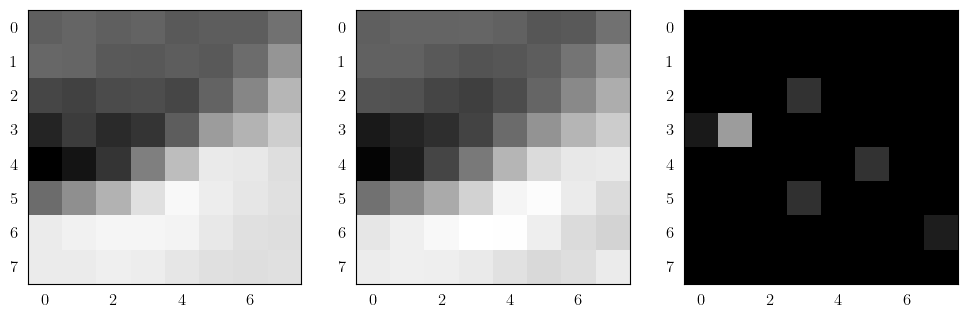

In [5]:
# DCT
dct = fft.dctn(crop, norm='ortho')

# Compression mask*, no
mask = np.ones((8,8))
for x in range(8):
    for y in range(8):
        if x+y>=7:
            mask[y,x]=0

# Inverse DCT
crop_comp = fft.idctn(dct*mask, norm='ortho')

# Comparison (before and after compression)
fig, axs = plt.subplots(1, 3, figsize=(12,5))
vmin = min(crop.min(), crop_comp.min())
vmax = max(crop.max(), crop_comp.max())
axs[0].imshow(crop, cmap="gray", vmin=vmin, vmax=vmax)
axs[1].imshow(crop_comp, cmap="gray", vmin=vmin, vmax=vmax)
axs[2].imshow((crop-crop_comp)*10, cmap="gray", vmin=vmin, vmax=vmax)

plt.savefig("squirrel-comparison.svg")

### DCT coefficients

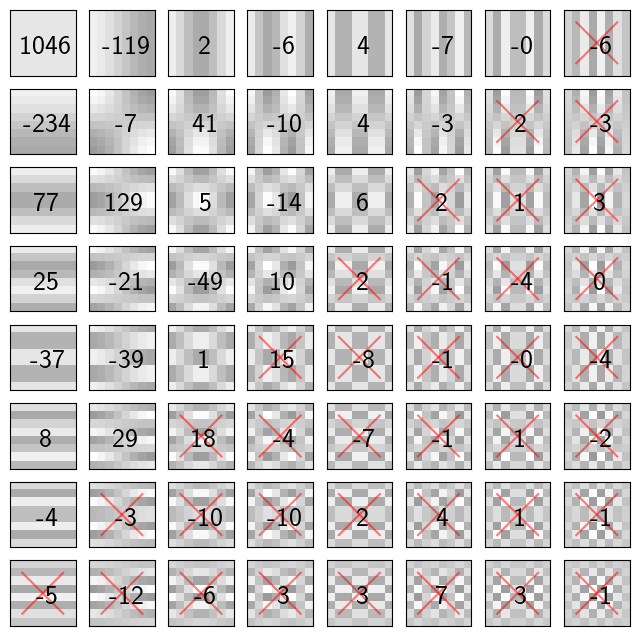

In [6]:
fig = plt.figure(figsize=(8,8))
for x in range(8):
    for y in range(8):
    
        # DCT (nulle partout sauf au pixel p)
        F = np.zeros((8,8))
        F[y,x] = 1

        # DCT inverse (ne pas oublier l'option norm='ortho' !)
        f = fft.idctn(F, norm='ortho')
        
        # Affichage de l'image de la base
        plt.subplot(8, 8, 8*y+x+1)
        plt.imshow(f, "gray", vmin=-1, vmax=.25)
        
        if mask[y,x] == 0:
            plt.plot([1,6], [1,6], color="#ff000080")
            plt.plot([1,6], [6,1], color="#ff000080")
        
        plt.text(4, 4, f"{dct[y,x]:.0f}", ha='center', va='center', size=20)
        
        plt.xticks([])
        plt.yticks([])
        
plt.savefig("squirrel-coefficients.svg")